# 05 物流与体验（MySQL + Python 可视化）

**数据源**：MySQL `olist`（主要用 `v_order_base`）
**分析逻辑**：执行 `analysis_code/05_logistics_experience.sql`（6 条查询）
**口径**：物流相关指标只取**已送达**订单；运费占比 = 运费 / 商品价格


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 找到项目根（含 analysis_code/ 的目录），兼容从 notebooks/ 或项目根启动
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_code").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks"))
import db

# 先设 seaborn 主题，再设中文字体（顺序不能反）
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

print("project root:", PROJECT_ROOT)
print("sql dir:", db.SQL_DIR)

project root: C:\Users\iiLI\Desktop\1
sql dir: C:\Users\iiLI\Desktop\1\analysis_code


## 1. 执行 SQL

In [2]:
results = db.run_sql_file(db.SQL_DIR / "05_logistics_experience.sql")
overview, delay, legs, state, freight, seller = results

for name, df in zip(["overview", "delay", "legs", "state", "freight", "seller"], results):
    print(f"{name:10s} {df.shape}")

overview

overview   (1, 4)
delay      (4, 5)
legs       (2, 4)
state      (10, 5)
freight    (15, 5)
seller     (608, 3)


,total_delivered_orders,avg_delivery_day,late_rate_pct,avg_review_score
0,96203,12.5,6.79,4.16


## 2. 图 1：延迟分桶 vs 评分 / 差评率

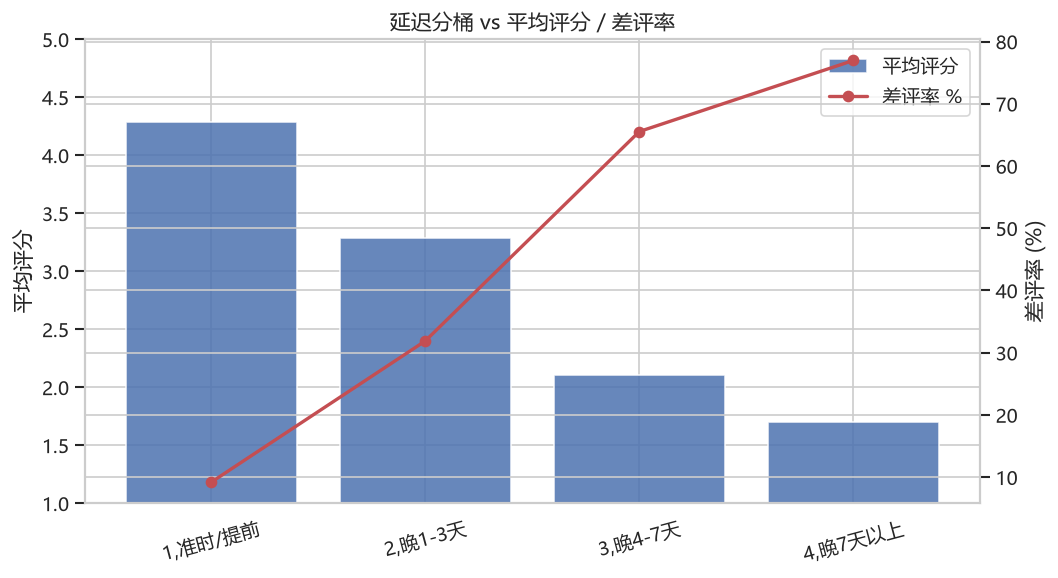

1,准时/提前: 89672 单 | 评分 4.29 | 差评率 9.19%
2,晚1-3天: 1869 单 | 评分 3.29 | 差评率 31.89%
3,晚4-7天: 1802 单 | 评分 2.11 | 差评率 65.54%
4,晚7天以上: 2860 单 | 评分 1.7 | 差评率 76.96%


In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(delay["delay_bucket"], delay["avg_review_score"], color="#4C72B0", alpha=0.85, label="平均评分")
ax.set_ylabel("平均评分")
ax.set_ylim(1, 5)
ax.tick_params(axis="x", rotation=15)

ax2 = ax.twinx()
ax2.plot(delay["delay_bucket"], delay["bad_review_rate_pct"], color="#C44E52", marker="o", lw=2, label="差评率 %")
ax2.set_ylabel("差评率 (%)")

ax.set_title("延迟分桶 vs 平均评分 / 差评率")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")

plt.tight_layout()
plt.show()

for _, r in delay.iterrows():
    print(f"{r['delay_bucket']}: {int(r['total_orders'])} 单 | 评分 {r['avg_review_score']} | 差评率 {r['bad_review_rate_pct']}%")

### 观察
- 迟到越久，评分单调下降，差评率在2-3时陡增
- 「晚 1-3 天」和「准时」差距较大，说明用户对轻微延迟的容忍度不行。


## 3. 图 2：卖家处理段 vs 承运配送段

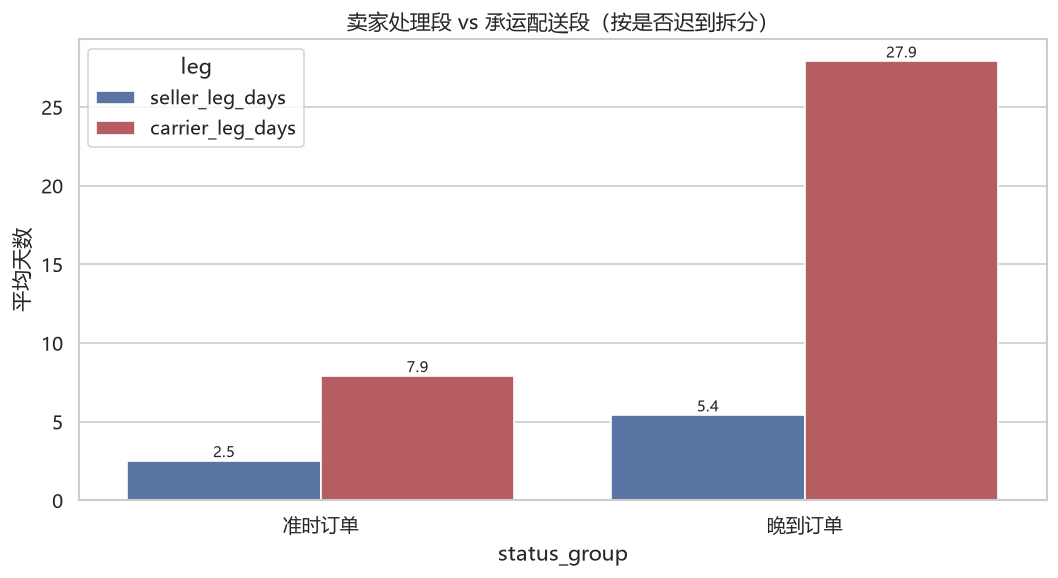

In [4]:
legs_melt = legs.melt(
    id_vars="status_group",
    value_vars=["seller_leg_days", "carrier_leg_days"],
    var_name="leg",
    value_name="days",
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=legs_melt, x="status_group", y="days", hue="leg", ax=ax,
            palette=["#4C72B0", "#C44E52"])
ax.set_ylabel("平均天数")
ax.set_title("卖家处理段 vs 承运配送段（按是否迟到拆分）")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=9)
plt.tight_layout()
plt.show()

### 观察
- 迟到订单主要慢在「承运配送」
- 这说明了优化责任归物流商。


## 4. 图 3：各州迟到率

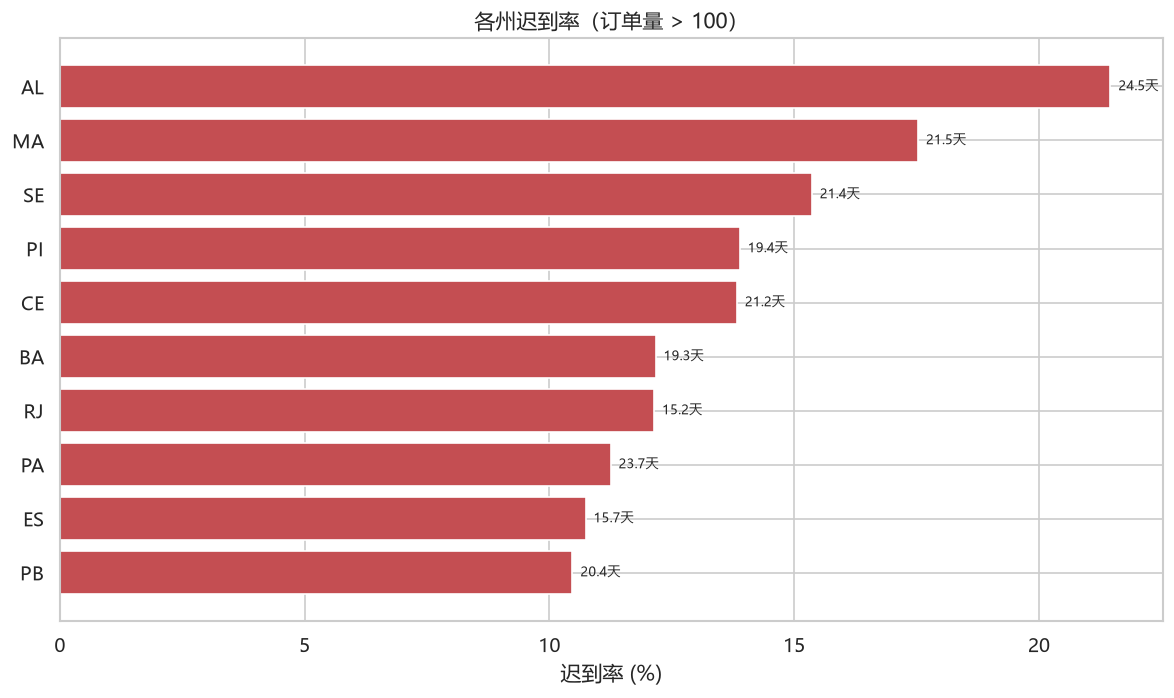

In [5]:
st = state.sort_values("late_rate_pct")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(st["customer_state"], st["late_rate_pct"], color="#C44E52")
ax.set_xlabel("迟到率 (%)")
ax.set_title("各州迟到率（订单量 > 100）")
for bar, days in zip(bars, st["avg_delivery_days"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {days:.1f}天", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### 观察（你来补）
- AL州是「重灾区」，平均送达天数约长迟到率约高
- 这些州的地理/物流特征：巴西的物流基建高度集中在东南部（如圣保罗、里约）。东北部和北部距离经济中心非常远，且公路、铁路等陆运基建相对落后（PA州甚至极其依赖水运），导致货物从东南部大仓发往东北部/北部时，运输时间长、中转多，极易发生延误。


## 5. 图 4：运费占比最高的品类

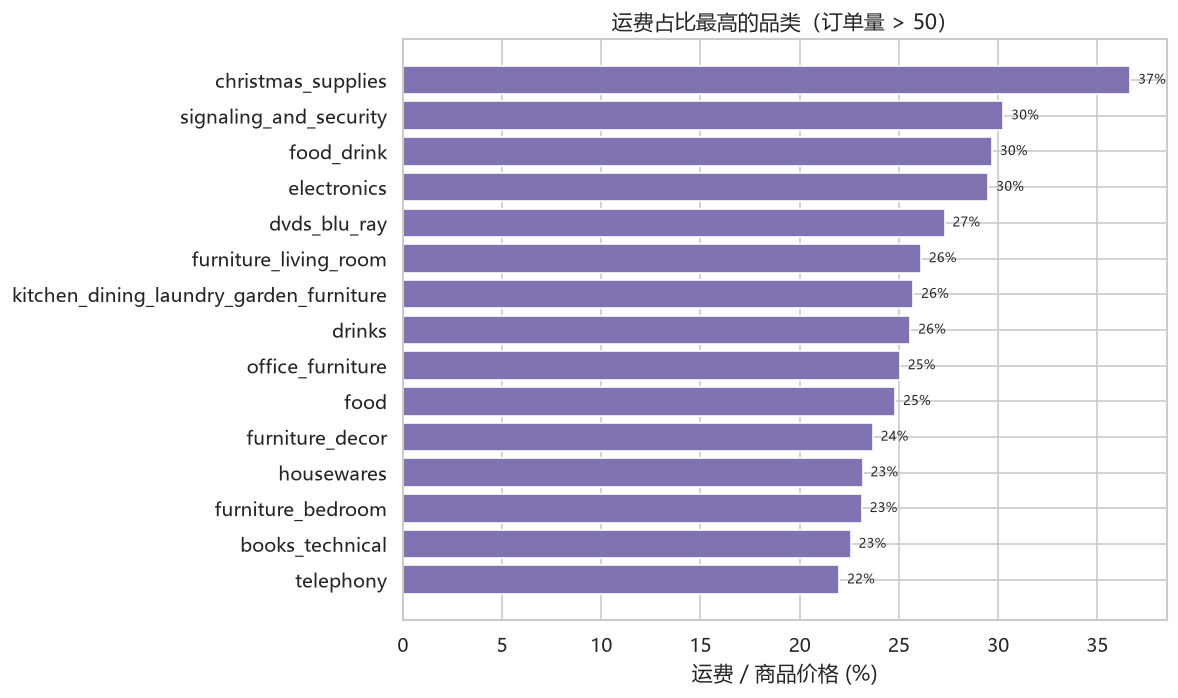

In [6]:
fr = freight.sort_values("freight_ratio_pct")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(fr["category"], fr["freight_ratio_pct"], color="#8172B2")
ax.set_xlabel("运费 / 商品价格 (%)")
ax.set_title("运费占比最高的品类（订单量 > 50）")
for bar, v in zip(ax.patches, fr["freight_ratio_pct"]):
    ax.text(v, bar.get_y() + bar.get_height() / 2, f"  {v:.0f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### 观察
- 运费占比畸高的品类：榜首：christmas_supplies（圣诞用品）一骑绝尘，运费占比高达 37%。
· 第二梯队：signaling_and_security（信号与安全设备）、food_drink（食品饮料）、electronics（电子产品），运费占比均为 30%。
· 第三梯队（集中在25%左右）：大量家具类（furniture_living_room客厅家具, kitchen...garden_furniture厨房花园家具, office_furniture办公家具, furniture_decor家居装饰, furniture_bedroom卧室家具），以及 drinks（饮料）、books_technical（技术书籍）。
- 是低价重货：是的，等别是家具类，饮料食品类典型的物理重量大或体积庞大。
- 对定价/包邮策略：进行区域定价；提高包邮门槛；定向包邮（会员制）


## 6. 卖家配送速度分布

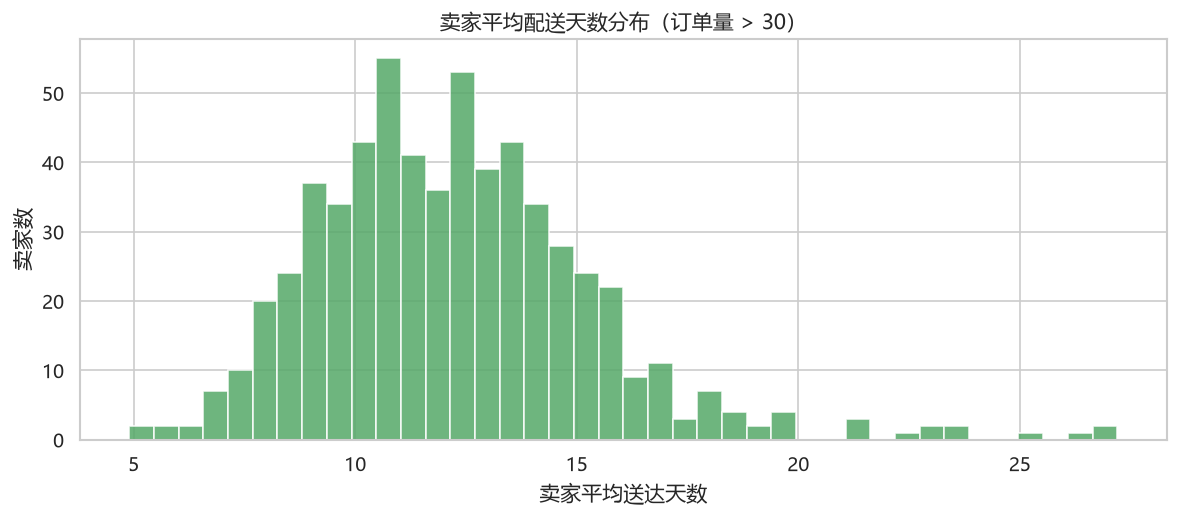

,seller_id,total_orders,avg_delivery_days
0,2a1348e9addc1af5aaa619b1a3679d6b,48,27.2
1,54965bbe3e4f07ae045b90b0b8541f52,73,26.7
2,5058e8c1e82653974541e83690655b4a,62,26.4
3,ad781527c93d00d89a11eecd9dcad7c1,38,25.4
4,712e6ed8aa4aa1fa65dab41fed5737e4,77,23.7
5,cee48807215b30a12ca2ca10ffb5f250,39,23.4
6,17f51e7198701186712e53a39c564617,56,22.8
7,d93919c944be9cff128f6c9cb899eacb,33,22.8
8,7c67e1448b00f6e969d365cea6b010ab,973,22.3
9,8444e55c1f13cd5c179851e5ca5ebd00,92,21.2


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(seller["avg_delivery_days"], bins=40, color="#55A868", alpha=0.85)
ax.set_xlabel("卖家平均送达天数")
ax.set_ylabel("卖家数")
ax.set_title("卖家平均配送天数分布（订单量 > 30）")
plt.tight_layout()
plt.show()

seller.nlargest(10, "avg_delivery_days")[["seller_id", "total_orders", "avg_delivery_days"]]